In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

df = pd.read_csv('customers.csv').drop(columns=['Row', 'CustomerId'])
df = df.fillna(df.mean())
X = ((df - df.mean()) / df.std()).values

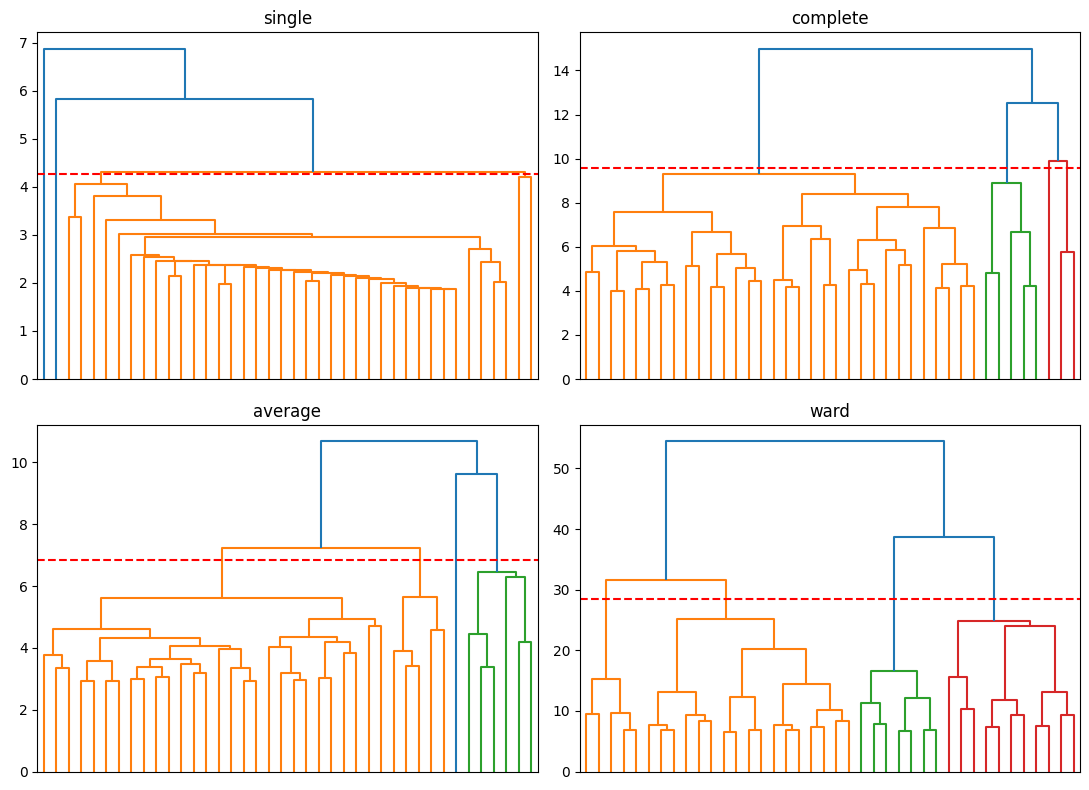

In [2]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

methods = ['single', 'complete', 'average', 'ward']
Zs = {m: linkage(X, method=m) for m in methods}
k = 4

plt.figure(figsize=(11, 8))
for i, m in enumerate(methods, 1):
    Z = Zs[m]
    plt.subplot(2, 2, i)
    dendrogram(Z, truncate_mode='lastp', p=40, no_labels=True)
    plt.axhline((Z[-k, 2] + Z[-k + 1, 2]) / 2, color='r', ls='--')
    plt.title(m)
plt.tight_layout(); plt.show()

single | размеры кластеров: [846   2   1   1] | ARI с k-Means: 0.005
complete | размеры кластеров: [836   7   6   1] | ARI с k-Means: 0.018
average | размеры кластеров: [832  10   7   1] | ARI с k-Means: 0.023
ward | размеры кластеров: [ 12 190 141 507] | ARI с k-Means: 0.35


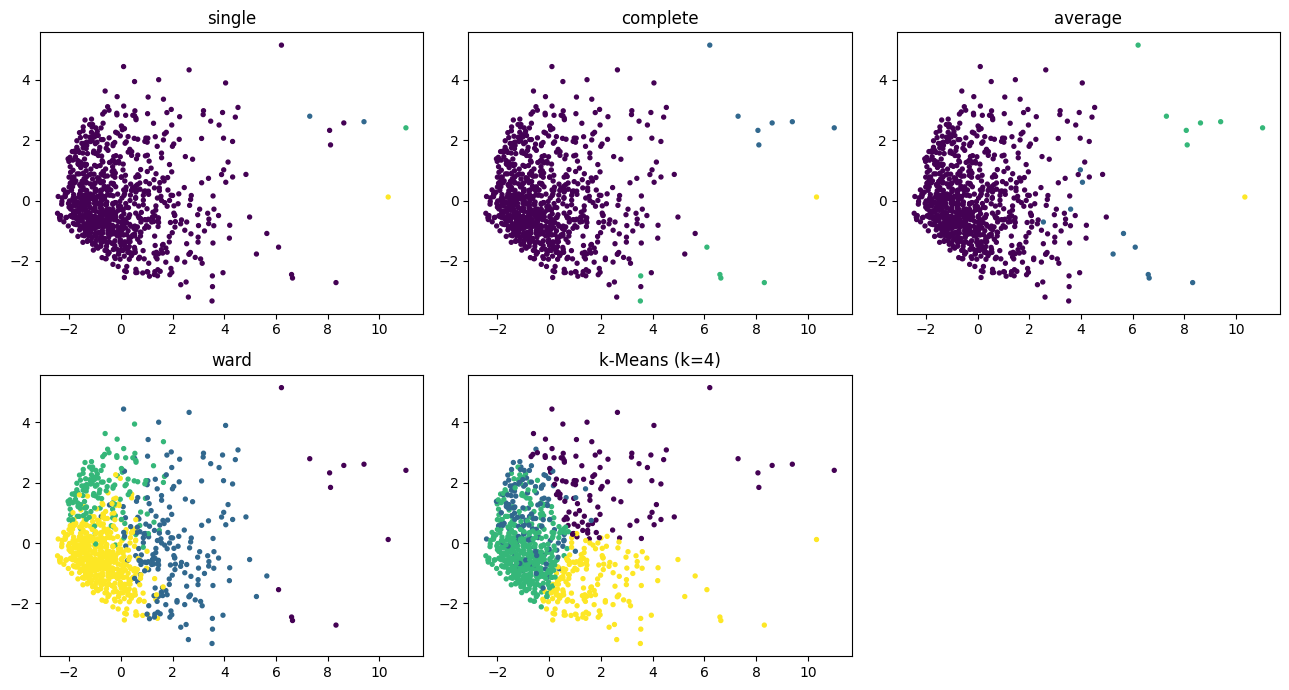

In [3]:
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score as ari

def kmeans(X, k, seed=0, iters=50):
    rng = np.random.default_rng(seed)
    C = X[rng.choice(len(X), k, replace=False)]
    for _ in range(iters):
        labels = ((X[:, None, :] - C[None, :, :]) ** 2).sum(-1).argmin(1)
        Cnew = np.array([X[labels == j].mean(0) if (labels == j).any() else C[j] for j in range(k)])
        if np.allclose(Cnew, C): break
        C = Cnew
    return ((X[:, None, :] - C[None, :, :]) ** 2).sum(-1).argmin(1)

labels_km = kmeans(X, k)
P = PCA(n_components=2).fit_transform(X)

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, m in zip(axes.ravel(), methods):
    lab = fcluster(Zs[m], k, criterion='maxclust')
    ax.scatter(P[:, 0], P[:, 1], c=lab, cmap='viridis', s=8)
    ax.set_title(m)
    print(m, '| размеры кластеров:', np.bincount(lab)[1:], '| ARI с k-Means:', round(ari(lab, labels_km), 3))
axes.ravel()[4].scatter(P[:, 0], P[:, 1], c=labels_km, cmap='viridis', s=8)
axes.ravel()[4].set_title('k-Means (k=4)')
axes.ravel()[5].axis('off')
plt.tight_layout(); plt.show()